# Eksploracja danych — brakujące wartości

**Cel zajęć:** nauczyć się *znajdować* braki (także te ukryte), *diagnozować*, czy są przypadkowe, i *świadomie wybierać*, czy je usunąć, czy uzupełnić.

**Plan:**
1. Rozgrzewka na zbiorze **Titanic** — te same kroki co na wykładzie.
2. Zadanie główne: **oferty mieszkań** (`nieruchomosci.csv`) — prawdziwy bałagan.

**Zadania:** 🟢 podstawowe (obowiązkowe), 🔵 dla ambitnych.

**Jak pracować:** w Colabie wybierz *Plik → Zapisz kopię na Dysku*, wgraj plik `nieruchomosci.csv` (ikona folderu po lewej → *Prześlij*), rozwiąż zadania w miejscach `# TODO`, a gotowy notatnik umieść w swoim repozytorium na GitHubie.

In [110]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams.update({"figure.figsize": (7, 4), "font.size": 11})

URL_TITANIC = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
titanic = pd.read_csv("titanic.csv") if Path("titanic.csv").exists() else pd.read_csv(URL_TITANIC)

if not Path("nieruchomosci.csv").exists():
    print("⚠️ Wgraj plik nieruchomosci.csv do bieżącego katalogu (w Colabie: ikona folderu → Prześlij).")

print(titanic.shape)
titanic.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


---
# Część 1. Rozgrzewka: Titanic

| kolumna | znaczenie |
|---|---|
| `Survived` | czy pasażer przeżył (1 = tak) |
| `Pclass` | klasa biletu (1, 2, 3) |
| `Sex`, `Age` | płeć, wiek |
| `SibSp`, `Parch` | liczba rodzeństwa/małżonków oraz rodziców/dzieci na pokładzie |
| `Fare` | cena biletu (£) |
| `Cabin` | numer kabiny |
| `Embarked` | port zaokrętowania: C — Cherbourg, Q — Queenstown, S — Southampton |

### 🟢 Zadanie 1: ile jest braków?

1. Policz liczbę i odsetek braków w każdej kolumnie. Pokaż tylko kolumny, w których braki występują, posortowane malejąco.
2. Narysuj poziomy wykres słupkowy odsetka braków (`.plot.barh()`), z opisem osi.

          liczba  odsetek [%]
Cabin        687        77.10
Age          177        19.87
Embarked       2         0.22


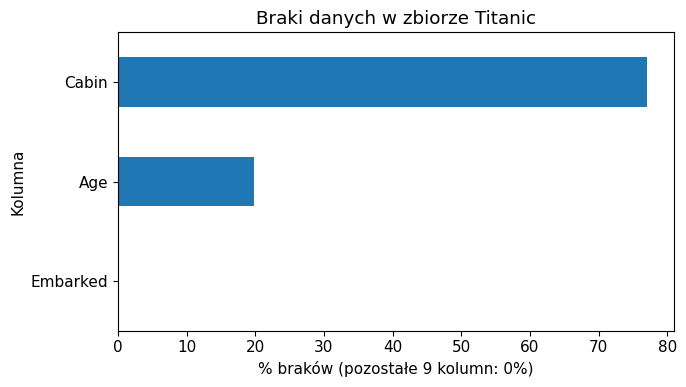

In [111]:
# 1. liczba i odsetek braków w każdej kolumnie
braki = titanic.isna().sum()
braki = braki[braki > 0].sort_values(ascending=False)

tabela_brakow = pd.DataFrame({
    "liczba": braki,
    "odsetek [%]": (braki / len(titanic) * 100).round(2)
})
print(tabela_brakow)

# 2. wykres odsetka braków
ax = tabela_brakow["odsetek [%]"].sort_values().plot.barh()
ax.set_xlabel("% braków (pozostałe 9 kolumn: 0%)")
ax.set_ylabel("Kolumna")
ax.set_title("Braki danych w zbiorze Titanic")
plt.tight_layout()
plt.show()

### 🟢 Zadanie 2: mapa braków

Narysuj mapę braków (`sns.heatmap(titanic.isna(), cbar=False)`) dla kolumn `Age`, `Cabin`, `Embarked` — najpierw z wierszami w oryginalnej kolejności, a potem **posortowanymi według klasy** (`Pclass`). Dwa wykresy obok siebie.

Co widać na drugim wykresie, czego nie było widać na pierwszym?

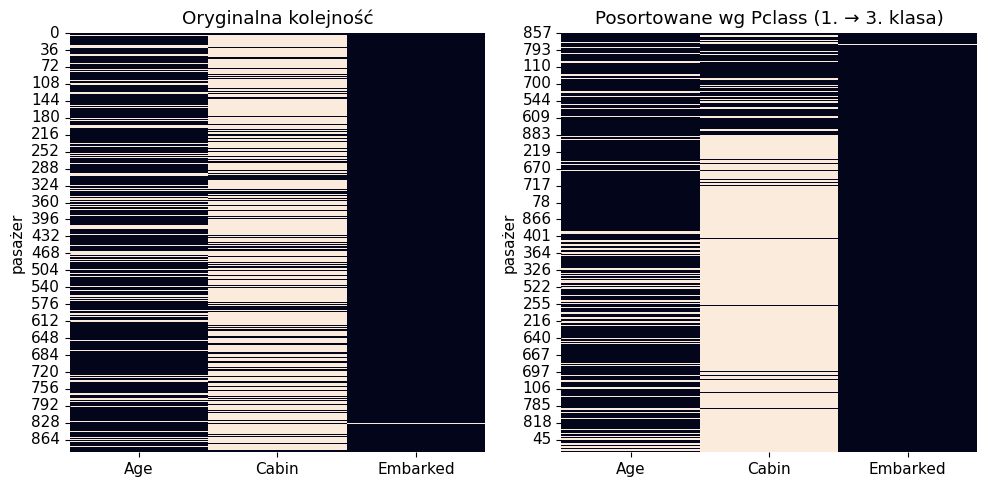

In [112]:
kolumny = ["Age", "Cabin", "Embarked"]

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# 1. wiersze w oryginalnej kolejności
sns.heatmap(titanic[kolumny].isna(), cbar=False, ax=axes[0])
axes[0].set_title("Oryginalna kolejność")
axes[0].set_ylabel("pasażer")

# 2. wiersze posortowane według klasy
posortowane = titanic.sort_values("Pclass")
sns.heatmap(posortowane[kolumny].isna(), cbar=False, ax=axes[1])
axes[1].set_title("Posortowane wg Pclass (1. → 3. klasa)")
axes[1].set_ylabel("pasażer")

plt.tight_layout()
plt.show()

*Twoja odpowiedź:* Na drugim wykresie widać, że braki zależą od klasy. Np. w kolumnie Cabin w 1. klasie braków jest mało, a w 2. i 3. klasie prawie same braki. Na pierwszym wykresie tego nie było widać, bo braki wyglądały na rozrzucone losowo. Czyli braki nie są przypadkowe.

### 🟢 Zadanie 3: czy braki wieku są losowe?

1. Utwórz serię `brak_wieku = titanic["Age"].isna()`.
2. Policz odsetek braków wieku w każdej klasie i osobno dla każdej płci.
3. Porównaj odsetek ocalałych wśród osób ze znanym wiekiem i bez wieku.
4. Narysuj wyniki z punktów 2 i 3 na dwóch wykresach słupkowych.
5. Czy braki wieku to MCAR? Co by się stało z odsetkiem ocalałych, gdybyśmy usunęli wiersze bez wieku?

Odsetek pasażerów bez wieku w każdej klasie:
Pclass
1    13.9
2     6.0
3    27.7
Name: Age, dtype: float64

Odsetek pasażerów bez wieku wg płci:
Sex
female    16.9
male      21.5
Name: Age, dtype: float64

Odsetek ocalałych:
Age
False    40.6
True     29.4
Name: Survived, dtype: float64

Odsetek ocalałych wśród wszystkich pasażerów: 38.4
Odsetek ocalałych po usunięciu wierszy bez wieku: 40.6



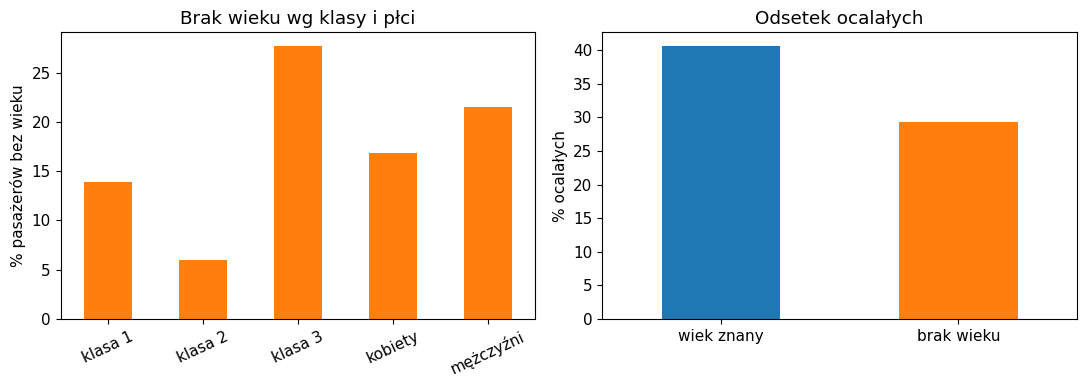

In [113]:
brak_wieku = titanic["Age"].isna()

# 2. odsetek braków wieku w każdej klasie i dla każdej płci
brak_klasa = brak_wieku.groupby(titanic["Pclass"]).mean() * 100
brak_plec = brak_wieku.groupby(titanic["Sex"]).mean() * 100

print("Odsetek pasażerów bez wieku w każdej klasie:")
print(brak_klasa.round(1))
print()
print("Odsetek pasażerów bez wieku wg płci:")
print(brak_plec.round(1))
print()

# 3. odsetek ocalałych: wiek znany vs brak wieku
przezyli = titanic.groupby(brak_wieku)["Survived"].mean() * 100

print("Odsetek ocalałych:")
print(przezyli.round(1))
print()
print("Odsetek ocalałych wśród wszystkich pasażerów:",
      round(titanic["Survived"].mean() * 100, 1))
print("Odsetek ocalałych po usunięciu wierszy bez wieku:",
      round(titanic.dropna(subset=["Age"])["Survived"].mean() * 100, 1))
print()

# 4. wykresy słupkowe
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# 1. wykres: odsetek braków wieku (klasa i płeć)
dane_braki = pd.concat([
    brak_klasa.rename(lambda x: f"klasa {x}"),
    brak_plec.rename({"female": "kobiety", "male": "mężczyźni"})
])
dane_braki.plot.bar(ax=axes[0], rot=25, color="tab:orange")
axes[0].set_ylabel("% pasażerów bez wieku")
axes[0].set_title("Brak wieku wg klasy i płci")

# 2. wykres: odsetek ocalałych
przezyli.index = ["wiek znany", "brak wieku"]
przezyli.plot.bar(ax=axes[1], rot=0, color=["tab:blue", "tab:orange"])
axes[1].set_ylabel("% ocalałych")
axes[1].set_title("Odsetek ocalałych")

plt.tight_layout()
plt.show()

*Twoja odpowiedź:* Nie, braki wieku nie są losowe, czyli to nie MCAR.

W 3. klasie wieku brakuje u 27,7% pasażerów, a w 2. klasie tylko u 6%. Osoby bez wieku rzadziej przeżyły niż te z wiekiem. Brak wieku zależy więc od innych rzeczy, np. od klasy. Gdybyśmy usunęli wiersze bez wieku, odsetek ocalałych zostałby zawyżony.

### 🟢 Zadanie 4: ile kosztuje usuwanie?

Dla czterech wariantów — bez zmian, `dropna(subset=["Embarked"])`, `dropna(subset=["Age"])`, `dropna()` — zbuduj tabelę z kolumnami:
- liczba wierszy,
- odsetek ocalałych,
- odsetek pasażerów 1. klasy.

Który wariant najbardziej zniekształca dane i dlaczego?

In [114]:
warianty = {
    "bez zmian": titanic,
    'dropna(subset=["Embarked"])': titanic.dropna(subset=["Embarked"]),
    'dropna(subset=["Age"])': titanic.dropna(subset=["Age"]),
    "dropna()": titanic.dropna(),
}

tabela = pd.DataFrame({
    "liczba wierszy": {n: len(d) for n, d in warianty.items()},
    "ocalali [%]": {n: d["Survived"].mean() * 100 for n, d in warianty.items()},
    "1. klasa [%]": {n: (d["Pclass"] == 1).mean() * 100 for n, d in warianty.items()},
}).round(1)

tabela

,liczba wierszy,ocalali [%],1. klasa [%]
bez zmian,891,38.4,24.2
"dropna(subset=[""Embarked""])",889,38.2,24.1
"dropna(subset=[""Age""])",714,40.6,26.1
dropna(),183,67.2,86.3


*Twoja odpowiedź:* Najbardziej zniekształca dane dropna(). Zostaje tylko 183 pasażerów z 891. Dzieje się tak, bo prawie wszyscy z 2. i 3. klasy nie mają numeru kabiny, więc dropna() usuwa ich niemal wszystkich. Zostają głównie bogatsi pasażerowie, którzy częściej przeżyli, więc dane nie są już reprezentatywne.

### 🟢 Zadanie 5: uzupełnianie wieku

1. **Najpierw** dodaj kolumnę-flagę `Age_brak`.
2. Utwórz dwie wersje kolumny wieku:
   - `wiek_srednia` — braki uzupełnione średnią,
   - `wiek_grupy` — braki uzupełnione medianą w grupach (klasa × płeć); wskazówka: `groupby(...)["Age"].transform("median")`.
3. Narysuj trzy histogramy obok siebie (te same przedziały, `bins=np.arange(0, 82, 2)`): znane wartości, `wiek_srednia`, `wiek_grupy`.
4. Porównaj odchylenia standardowe. Która metoda bardziej zniekształca rozkład?

Age             177
wiek_srednia      0
wiek_grupy        0
dtype: int64



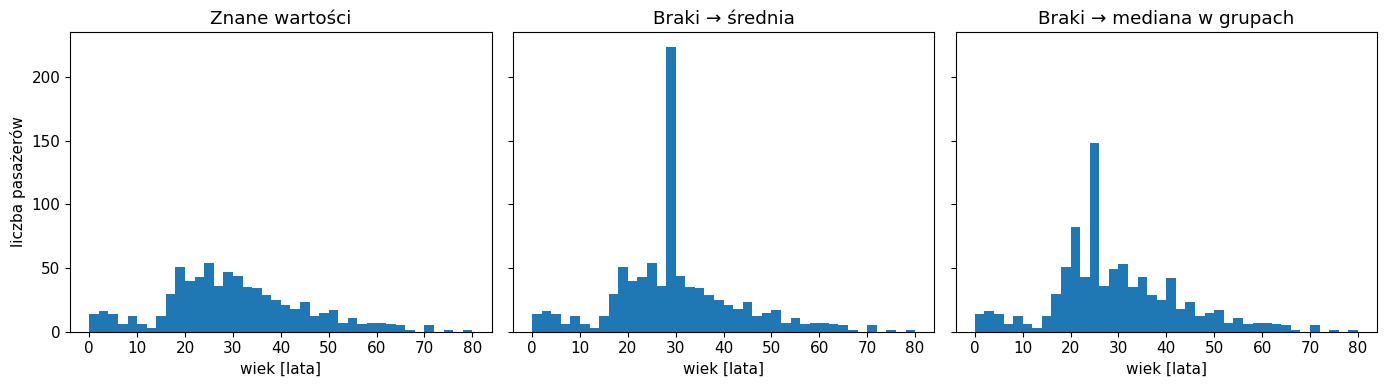

Odchylenie standardowe wieku:
  znane wartości:    14.53
  braki → średnia:   13.0
  braki → mediana w grupach: 13.3


In [115]:
# 1. flaga braku
titanic["Age_brak"] = titanic["Age"].isna()

# 2. uzupełnienie średnią
titanic["wiek_srednia"] = titanic["Age"].fillna(titanic["Age"].mean())

# 2. uzupełnienie medianą w grupach
mediana_grupy = titanic.groupby(["Pclass", "Sex"])["Age"].transform("median")
titanic["wiek_grupy"] = titanic["Age"].fillna(mediana_grupy)

# sprawdzenie, czy w nowych kolumnach nie ma już braków
print(titanic[["Age", "wiek_srednia", "wiek_grupy"]].isna().sum())
print()

# 3. histogramy
bins = np.arange(0, 82, 2)
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)

axes[0].hist(titanic["Age"].dropna(), bins=bins)
axes[0].set_title("Znane wartości")

axes[1].hist(titanic["wiek_srednia"], bins=bins)
axes[1].set_title("Braki → średnia")

axes[2].hist(titanic["wiek_grupy"], bins=bins)
axes[2].set_title("Braki → mediana w grupach")

for ax in axes:
    ax.set_xlabel("wiek [lata]")
axes[0].set_ylabel("liczba pasażerów")

plt.tight_layout()
plt.show()

# 4. odchylenia standardowe
print("Odchylenie standardowe wieku:")
print("  znane wartości:   ", round(titanic["Age"].std(), 2))
print("  braki → średnia:  ", round(titanic["wiek_srednia"].std(), 2))
print("  braki → mediana w grupach:", round(titanic["wiek_grupy"].std(), 2))

*Twoja odpowiedź:* Odchylenie standardowe dla znanych wartości wynosi 14,53, po uzupełnieniu średnią spada do 13,00, a po uzupełnieniu medianą w grupach do 13,30.

Bardziej zniekształca rozkład uzupełnianie średnią: odchylenie spadło najbardziej, a na histogramie widać duży sztuczny słupek przy wieku ok.30, bo wszystkie 177 osób dostało ten sam wiek.

Przy medianie w grupach słupki są mniej wysokie, bo brakujące wieki rozłożyły się na kilka wartości. Mediana w grupach jest więc lepsza, choć też nie odtwarza rozkładu idealnie.

### 🔵 Zadanie 6 (dla ambitnych): imputacja modelem

Uzupełnij wiek za pomocą `IterativeImputer` z biblioteki scikit-learn, wykorzystując kolumny `Pclass`, `SibSp`, `Parch`, `Fare` oraz płeć zakodowaną jako 0/1. Porównaj histogram i odchylenie standardowe z wynikami zadania 5.

```python
from sklearn.experimental import enable_iterative_imputer  # wymagane!
from sklearn.impute import IterativeImputer
```

Braki w wiek_model: 0



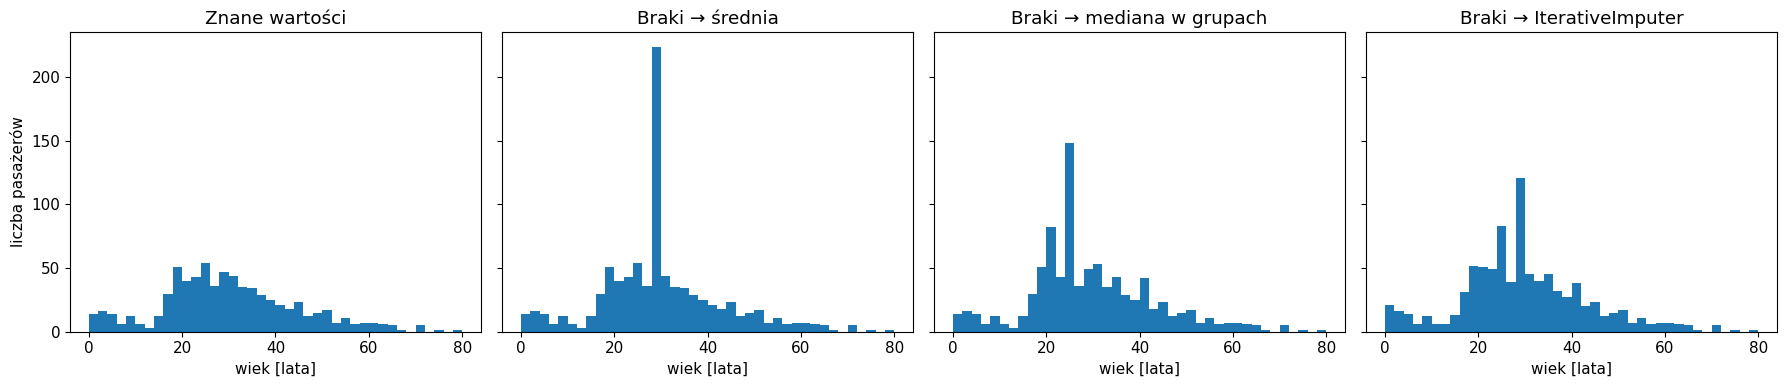

Odchylenie standardowe wieku:
  znane wartości:            14.53
  braki → średnia:           13.0
  braki → mediana w grupach: 13.3
  braki → IterativeImputer:  13.53


In [116]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

# wiek + cechy, z których będziemy go przewidywać
dane = titanic[["Age", "Pclass", "SibSp", "Parch", "Fare"]].copy()
dane["Sex"] = (titanic["Sex"] == "male").astype(int)   # mężczyzna = 1, kobieta = 0

imputer = IterativeImputer(random_state=0, max_iter=10, min_value=0)
wynik = imputer.fit_transform(dane)

# pierwsza kolumna wyniku to uzupełniony wiek
titanic["wiek_model"] = wynik[:, 0]

print("Braki w wiek_model:", titanic["wiek_model"].isna().sum())
print()

# histogramy
bins = np.arange(0, 82, 2)
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)

axes[0].hist(titanic["Age"].dropna(), bins=bins)
axes[0].set_title("Znane wartości")

axes[1].hist(titanic["wiek_srednia"], bins=bins)
axes[1].set_title("Braki → średnia")

axes[2].hist(titanic["wiek_grupy"], bins=bins)
axes[2].set_title("Braki → mediana w grupach")

axes[3].hist(titanic["wiek_model"], bins=bins)
axes[3].set_title("Braki → IterativeImputer")

for ax in axes:
    ax.set_xlabel("wiek [lata]")
axes[0].set_ylabel("liczba pasażerów")

plt.tight_layout()
plt.show()

# odchylenia standardowe
print("Odchylenie standardowe wieku:")
print("  znane wartości:           ", round(titanic["Age"].std(), 2))
print("  braki → średnia:          ", round(titanic["wiek_srednia"].std(), 2))
print("  braki → mediana w grupach:", round(titanic["wiek_grupy"].std(), 2))
print("  braki → IterativeImputer: ", round(titanic["wiek_model"].std(), 2))

IterativeImputer dał najlepszy wynik, odchylenie standardowe (13,53) jest najbliższe oryginałowi (14,53), a na histogramie nie ma sztucznego słupka, bo model przewidział dla każdego pasażera inną wartość na podstawie innych kolumn.

---
# Część 2. Zadanie główne: oferty mieszkań

**Dane:** plik `nieruchomosci.csv` — 45 ofert sprzedaży mieszkań w pięciu miastach.

| kolumna | znaczenie |
|---|---|
| `powierzchnia` | powierzchnia mieszkania [m²] |
| `rok_budowy` | rok budowy budynku |
| `pietro`, `liczba_pieter` | piętro mieszkania (0 = parter) i liczba pięter budynku |
| `parking`, `balkon` | Tak / Nie |
| `stan` | stan mieszkania |
| `cena_m2`, `cena_total` | cena za m² i cena całkowita [zł] |

Plik przygotował ktoś, kto różne braki zapisywał na różne sposoby. Twoim zadaniem jest je znaleźć i rozsądnie obsłużyć.

### 🟢 Zadanie 7: pierwszy rzut oka

1. Wczytaj plik bez żadnych dodatkowych parametrów i sprawdź typy kolumn (`dtypes`).
2. Policz braki (`isna().sum()`). Ile braków widzi pandas?
3. Dlaczego kolumna `powierzchnia` nie jest liczbowa, choć zawiera powierzchnię w m²?

In [117]:
mieszkania = pd.read_csv("nieruchomosci.csv")

# 1. typy kolumn
print("Typy kolumn:")
print(mieszkania.dtypes)
print()

# 2. liczba braków, które widzi pandas
print("Braki widziane przez pandas:")
print(mieszkania.isna().sum())
print()
print("Razem:", mieszkania.isna().sum().sum())

Typy kolumn:
id                int64
miasto           object
dzielnica        object
powierzchnia     object
liczba_pokoi      int64
rok_budowy       object
pietro           object
liczba_pieter     int64
parking          object
balkon           object
stan             object
cena_m2           int64
cena_total        int64
dtype: object

Braki widziane przez pandas:
id               0
miasto           0
dzielnica        0
powierzchnia     4
liczba_pokoi     0
rok_budowy       4
pietro           0
liczba_pieter    0
parking          0
balkon           0
stan             0
cena_m2          0
cena_total       0
dtype: int64

Razem: 8


*Twoja odpowiedź:* Pandas widzi tylko 8 braków: po 4 w kolumnach powierzchnia i rok_budowy.

Kolumna powierzchnia nie jest liczbowa, bo oprócz liczb zawiera napis "brak". Jedna wartość tekstowa wystarczy, żeby pandas wczytał całą kolumnę jako tekst.



### 🟢 Zadanie 8: braki „w przebraniu”

1. Dla każdej kolumny tekstowej i każdej kolumny liczbowej obejrzyj występujące wartości (`value_counts(dropna=False)` albo `unique()`). Wypisz wszystkie wartości, które oznaczają brak.
2. **Pułapka:** w kolumnach `powierzchnia` i `pietro` występuje `0`. Czy w obu przypadkach to brak danych?
3. Wczytaj plik ponownie z parametrem `na_values` podanym jako **słownik** (kolumna → lista wartości), tak aby każda kolumna miała tylko „swoje” oznaczenia braków.
4. Sprawdź typy kolumn i policz braki jeszcze raz.

In [118]:
for kolumna in mieszkania.columns.drop(["id", "dzielnica", "cena_total"]):
    print("==", kolumna)
    print(mieszkania[kolumna].value_counts(dropna=False).sort_index())
    print()

== miasto
miasto
Gdańsk      9
Kraków      9
Poznań      9
Warszawa    9
Wrocław     9
Name: count, dtype: int64

== powierzchnia
powierzchnia
0       3
42      1
45      1
46      1
48      2
50      1
51      1
52      1
54      1
55      2
56      1
58      2
60      2
62      2
64      1
65      1
66      1
68      1
69      1
70      2
72      2
75      1
76      1
78      1
80      1
82      1
85      1
88      1
90      1
95      1
brak    2
NaN     4
Name: count, dtype: int64

== liczba_pokoi
liczba_pokoi
1     4
2    15
3    18
4     7
5     1
Name: count, dtype: int64

== rok_budowy
rok_budowy
1995    1
1996    1
1997    1
1998    1
1999    1
2000    1
2001    1
2002    1
2003    1
2004    1
2005    1
2006    1
2007    1
2008    1
2009    1
2010    2
2011    2
2012    1
2013    2
2014    2
2015    2
2016    2
2017    2
2018    2
2019    2
2020    2
2021    1
2022    1
brak    3
NaN     4
Name: count, dtype: int64

== pietro
pietro
-999    2
0       3
1       8
2       9
3    

*Twoja odpowiedź:* Wartości oznaczające brak to: NA, N/A, brak, ?, -999, -1 oraz 0.

Pułapka z zerem: w powierzchnia zero to brak danych, bo mieszkanie nie może mieć 0 m2. W pietro zero oznacza parter, więc to prawdziwa wartość i nie wolno jej traktować jako braku.

In [119]:
braki_slownik = {
    "powierzchnia": ["brak", "0"],
    "rok_budowy": ["brak"],
    "pietro": ["brak", "-999"],
    "parking": ["?"],
    "balkon": ["?"],
    "cena_m2": ["-1", "-999"],
}

mieszkania = pd.read_csv("nieruchomosci.csv", na_values=braki_slownik)

print("Typy kolumn:")
print(mieszkania.dtypes)
print()
print("Braki w kolumnach:")
print(mieszkania.isna().sum())
print()
print("Razem:", mieszkania.isna().sum().sum())

Typy kolumn:
id                 int64
miasto            object
dzielnica         object
powierzchnia     float64
liczba_pokoi       int64
rok_budowy       float64
pietro           float64
liczba_pieter      int64
parking           object
balkon            object
stan              object
cena_m2          float64
cena_total         int64
dtype: object

Braki w kolumnach:
id               0
miasto           0
dzielnica        0
powierzchnia     9
liczba_pokoi     0
rok_budowy       7
pietro           3
liczba_pieter    0
parking          5
balkon           3
stan             0
cena_m2          2
cena_total       0
dtype: int64

Razem: 29


### 🟢 Zadanie 9: dziwna kategoria

Obejrzyj wartości w kolumnie `stan`. Jedna z nich nie pasuje do pozostałych. Co mogła oznaczać i jak ją poprawić? Zaproponuj i zastosuj rozwiązanie (uzasadnij je).

In [120]:
# kategorie w kolumnie stan
print(mieszkania["stan"].value_counts(dropna=False))
print()

# wiersz z dziwną wartością
print(mieszkania[mieszkania["stan"] == "很好"][["id", "miasto", "dzielnica", "stan"]])
print()

# poprawka
mieszkania["stan"] = mieszkania["stan"].replace({"很好": "Bardzo dobry"})

print(mieszkania["stan"].value_counts(dropna=False))

stan
Dobry           28
Bardzo dobry    11
Do remontu       5
很好               1
Name: count, dtype: int64

   id  miasto  dzielnica stan
1   2  Kraków  Krowodrza   很好

stan
Dobry           28
Bardzo dobry    12
Do remontu       5
Name: count, dtype: int64


Wartość 很好 to po chińsku „bardzo dobry”, więc pasuje do kategorii Bardzo dobry. Prawdopodobnie ktoś wpisał ją w innym języku. To nie jest brak danych, bo wartość da się zrozumieć, więc zamieniam ją na Bardzo dobry zamiast na NaN. Dzięki temu nie tracimy informacji i kategorie są spójne.

### 🟢 Zadanie 10: mapa braków

1. Narysuj odsetek braków w kolumnach (wykres słupkowy) i mapę braków.
2. Czy braki w różnych kolumnach występują w tych samych wierszach? (Wskazówka: `mieszkania.isna().corr()` dla kolumn z brakami.)

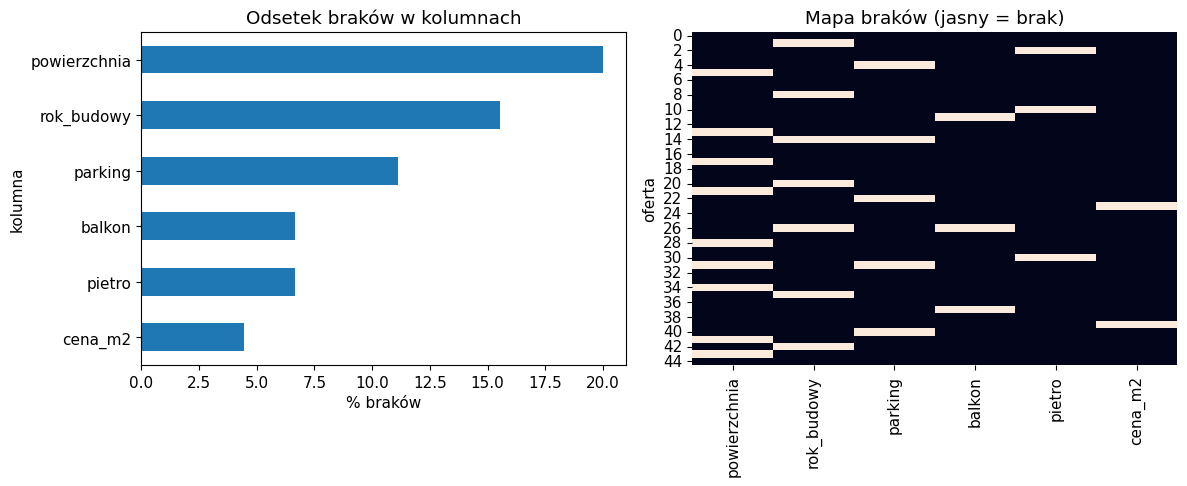

Odsetek braków [%]:
cena_m2          4.4
pietro           6.7
balkon           6.7
parking         11.1
rok_budowy      15.6
powierzchnia    20.0
dtype: float64

Korelacja braków między kolumnami:
              powierzchnia  rok_budowy  parking  balkon  pietro  cena_m2
powierzchnia          1.00       -0.21    -0.00   -0.13   -0.13    -0.11
rok_budowy           -0.21        1.00     0.04    0.13   -0.11    -0.09
parking              -0.00        0.04     1.00   -0.09   -0.09    -0.08
balkon               -0.13        0.13    -0.09    1.00   -0.07    -0.06
pietro               -0.13       -0.11    -0.09   -0.07    1.00    -0.06
cena_m2              -0.11       -0.09    -0.08   -0.06   -0.06     1.00

Liczba braków w jednym wierszu (liczba ofert):
0    19
1    23
2     3
Name: count, dtype: int64


In [121]:
# kolumny, w których są braki
braki = mieszkania.isna().mean() * 100
braki = braki[braki > 0].sort_values()
kolumny_z_brakami = list(braki.index[::-1])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 1. wykres słupkowy
braki.plot.barh(ax=axes[0])
axes[0].set_xlabel("% braków")
axes[0].set_ylabel("kolumna")
axes[0].set_title("Odsetek braków w kolumnach")

# 1. mapa braków
sns.heatmap(mieszkania[kolumny_z_brakami].isna(), cbar=False, ax=axes[1])
axes[1].set_title("Mapa braków (jasny = brak)")
axes[1].set_ylabel("oferta")

plt.tight_layout()
plt.show()

# czy braki występują w tych samych wierszach
print("Odsetek braków [%]:")
print(braki.round(1))
print()
print("Korelacja braków między kolumnami:")
print(mieszkania[kolumny_z_brakami].isna().corr().round(2))
print()
print("Liczba braków w jednym wierszu (liczba ofert):")
print(mieszkania[kolumny_z_brakami].isna().sum(axis=1).value_counts().sort_index())

*Twoja odpowiedź:* Najwięcej braków jest w powierzchni i roku budowy. Braki nie występują w tych samych wierszach: korelacje są bliskie zeru, a tylko 3 oferty mają po 2 braki. Braki w różnych kolumnach są więc od siebie niezależne.

### 🟢 Zadanie 11: odtwórz, zamiast zgadywać

Sprawdź, czy dla wierszy bez braków zachodzi zależność `cena_total = powierzchnia × cena_m2`. Jeśli tak — wykorzystaj ją, żeby **odtworzyć** brakujące wartości w kolumnach `powierzchnia` i `cena_m2`. Ile braków udało się w ten sposób usunąć?

To jest „ręczne uzupełnianie” z wykładu: znamy prawdziwą wartość, więc nie musimy jej szacować.

In [122]:
# sprawdzenie
pelne = mieszkania.dropna(subset=["powierzchnia", "cena_m2"])
roznica = pelne["cena_total"] - pelne["powierzchnia"] * pelne["cena_m2"]

print("Liczba sprawdzonych wierszy:", len(pelne))
print("Największa różnica:", roznica.abs().max())
print("Wzór zachodzi wszędzie:", (roznica == 0).all())
print()

# braki przed odtworzeniem
przed = mieszkania[["powierzchnia", "cena_m2"]].isna().sum()
print("Braki przed:")
print(przed)
print()

# odtwarzanie brakujących wartości z cena_total
mieszkania["powierzchnia"] = mieszkania["powierzchnia"].fillna(
    mieszkania["cena_total"] / mieszkania["cena_m2"])
mieszkania["cena_m2"] = mieszkania["cena_m2"].fillna(
    mieszkania["cena_total"] / mieszkania["powierzchnia"])

# braki po odtworzeniu
po = mieszkania[["powierzchnia", "cena_m2"]].isna().sum()
print("Braki po:")
print(po)
print()
print("Udało się odtworzyć:")
print(przed - po)

Liczba sprawdzonych wierszy: 34
Największa różnica: 0.0
Wzór zachodzi wszędzie: True

Braki przed:
powierzchnia    9
cena_m2         2
dtype: int64

Braki po:
powierzchnia    0
cena_m2         0
dtype: int64

Udało się odtworzyć:
powierzchnia    9
cena_m2         2
dtype: int64


Udało się odtworzyć 11 braków: 9 w kolumnie powierzchnia i 2 w cena_m2

### 🟢 Zadanie 12: pozostałe braki

Dla każdej z kolumn `rok_budowy`, `pietro`, `parking`, `balkon`:
1. **Najpierw** dodaj kolumnę-flagę braku (np. `rok_budowy_brak`).
2. Zdecyduj, co zrobić z brakami, i zaimplementuj decyzję. Do rozważenia:
   - `rok_budowy` — mediana całościowa czy mediana w grupach? Jakie grupy mają sens: `miasto` czy `stan`? Policz mediany w obu podziałach, zanim wybierzesz.
   - `pietro` — są tylko 3 braki; mediana, a może coś mądrzejszego (np. środkowe piętro budynku: `liczba_pieter // 2`)?
   - `parking`, `balkon` — dominanta czy osobna kategoria `"nieznane"`? Co się stanie z odsetkiem mieszkań z parkingiem w każdym z tych wariantów?
3. Sprawdź, że w zbiorze nie ma już braków.

In [123]:
# 1. flagi braków
for kolumna in ["rok_budowy", "pietro", "parking", "balkon"]:
    mieszkania[kolumna + "_brak"] = mieszkania[kolumna].isna()

# 2. rok_budowy: mediany
print("rok_budowy - mediana całościowa:", mieszkania["rok_budowy"].median())
print()
print("Mediany wg miasta:")
print(mieszkania.groupby("miasto")["rok_budowy"].agg(["median", "count"]))
print()
print("Mediany wg stanu:")
print(mieszkania.groupby("stan")["rok_budowy"].agg(["median", "count"]))
print()

# decyzja: mediana w grupach wg stanu
mediana_stan = mieszkania.groupby("stan")["rok_budowy"].transform("median")
mieszkania["rok_budowy"] = mieszkania["rok_budowy"].fillna(mediana_stan)

# 2. pietro: środkowe piętro budynku
mieszkania["pietro"] = mieszkania["pietro"].fillna(mieszkania["liczba_pieter"] // 2)

# 2. parking i balkon: porównanie dominanty i kategorii "nieznane"
for kolumna in ["parking", "balkon"]:
    znane = mieszkania[kolumna].dropna()
    dominanta = mieszkania[kolumna].fillna(mieszkania[kolumna].mode()[0])
    nieznane = mieszkania[kolumna].fillna("nieznane")
    print(f"{kolumna} - odsetek 'Tak':")
    print("  tylko znane wartości:", round((znane == "Tak").mean() * 100, 1), "%")
    print("  braki -> dominanta:  ", round((dominanta == "Tak").mean() * 100, 1), "%")
    print("  braki -> 'nieznane': ", round((nieznane == "Tak").mean() * 100, 1), "%")
    print()

# decyzja: osobna kategoria "nieznane"
mieszkania["parking"] = mieszkania["parking"].fillna("nieznane")
mieszkania["balkon"] = mieszkania["balkon"].fillna("nieznane")

# 3. sprawdzenie, że nie ma już braków
print("Braki w całym zbiorze:", mieszkania.isna().sum().sum())
print()
print("Liczba uzupełnionych wartości (flagi):")
print(mieszkania[["rok_budowy_brak", "pietro_brak", "parking_brak", "balkon_brak"]].sum())
print()
print(mieszkania["parking"].value_counts())
print(mieszkania["balkon"].value_counts())

rok_budowy - mediana całościowa: 2011.5

Mediany wg miasta:
          median  count
miasto                 
Gdańsk    2001.5      8
Kraków    2013.0      7
Poznań    2013.5      8
Warszawa  2015.0      7
Wrocław   2011.0      8

Mediany wg stanu:
              median  count
stan                       
Bardzo dobry  2019.0     10
Do remontu    1997.0      5
Dobry         2010.0     23

parking - odsetek 'Tak':
  tylko znane wartości: 85.0 %
  braki -> dominanta:   86.7 %
  braki -> 'nieznane':  75.6 %

balkon - odsetek 'Tak':
  tylko znane wartości: 83.3 %
  braki -> dominanta:   84.4 %
  braki -> 'nieznane':  77.8 %

Braki w całym zbiorze: 0

Liczba uzupełnionych wartości (flagi):
rok_budowy_brak    7
pietro_brak        3
parking_brak       5
balkon_brak        3
dtype: int64

parking
Tak         34
Nie          6
nieznane     5
Name: count, dtype: int64
balkon
Tak         35
Nie          7
nieznane     3
Name: count, dtype: int64


### 🟢 Zadanie 13: porównaj przed i po

Wczytaj surowy plik jeszcze raz (z `na_values` z zadania 8) i porównaj z oczyszczoną wersją:
1. statystyki opisowe kolumn `powierzchnia`, `rok_budowy`, `cena_m2` (`describe()`),
2. histogram `rok_budowy` przed i po uzupełnieniu (dwa wykresy obok siebie, te same przedziały).

Czy uzupełnianie zmieniło rozkłady w istotny sposób?

Przed uzupełnieniem:
       powierzchnia  rok_budowy  cena_m2
count          36.0        38.0     43.0
mean           64.6      2010.3  10223.3
std            13.7         7.8   1611.7
min            42.0      1995.0   8200.0
25%            54.8      2004.2   9000.0
50%            63.0      2011.5   9800.0
75%            72.8      2016.8  11100.0
max            95.0      2022.0  15000.0

Po uzupełnieniu:
       powierzchnia  rok_budowy  cena_m2
count          45.0        45.0     45.0
mean           64.9      2010.6  10244.3
std            12.8         7.4   1623.9
min            42.0      1995.0   8200.0
25%            56.0      2006.0   9000.0
50%            62.0      2011.0   9800.0
75%            72.0      2017.0  11200.0
max            95.0      2022.0  15000.0


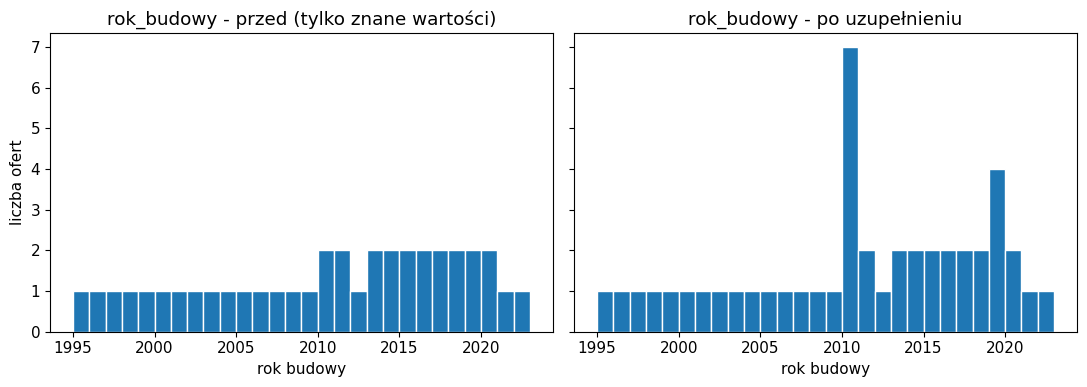

In [124]:
# surowe dane
surowe = pd.read_csv("nieruchomosci.csv", na_values=braki_slownik)

kolumny = ["powierzchnia", "rok_budowy", "cena_m2"]

# 1. statystyki opisowe przed i po
print("Przed uzupełnieniem:")
print(surowe[kolumny].describe().round(1))
print()
print("Po uzupełnieniu:")
print(mieszkania[kolumny].describe().round(1))

# 2. histogramy
bins = np.arange(surowe["rok_budowy"].min(), surowe["rok_budowy"].max() + 2, 1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

axes[0].hist(surowe["rok_budowy"].dropna(), bins=bins, edgecolor="white")
axes[0].set_title("rok_budowy - przed (tylko znane wartości)")

axes[1].hist(mieszkania["rok_budowy"], bins=bins, edgecolor="white")
axes[1].set_title("rok_budowy - po uzupełnieniu")

for ax in axes:
    ax.set_xlabel("rok budowy")
axes[0].set_ylabel("liczba ofert")

plt.tight_layout()
plt.show()

*Twoja odpowiedź:* Uzupełnianie nie zmieniło rozkładów w istotny sposób. Średnie i mediany prawie się nie zmieniły, a odchylenia standardowe lekko spadły. Na histogramie po uzupełnieniu widać jedynie wyższy słupek dla roku 2010 (oraz 2019), ponieważ brakujące oferty otrzymały medianę swojej grupy wg stanu.

### 🟢 Zadanie 14: zapisz decyzje

Uzupełnij tabelę. Dobra analiza danych to taka, którą ktoś inny może odtworzyć.

| Kolumna | Jak zapisano braki | Liczba braków | Decyzja | Uzasadnienie |
|---|---|---|---|---|
| `powierzchnia` | puste pole (NaN), `brak`, `0` | 9 | odtworzenie ze wzoru `cena_total / cena_m2` | wzór zachodzi we wszystkich pełnych wierszach, więc odzyskujemy prawdziwe wartości. Zero oznacza brak, bo mieszkanie nie może mieć 0 m² |
| `cena_m2` | `-1`, `-999` | 2 | odtworzenie ze wzoru `cena_total / powierzchnia` | jak wyżej, znamy prawdziwą wartość, więc jej nie szacujemy |
| `rok_budowy` | puste pole (NaN), `brak` | 7 | mediana w grupach według `stan` + flaga `rok_budowy_brak` | rok budowy nie ma tak oczywistej zależności jak cena, więc uzupełniamy medianą. Grupy według stanu, bo stan zależy od wieku budynku |
| `pietro` | `brak`, `-999` | 3 | `liczba_pieter // 2` + flaga `pietro_brak` | braków jest mało. Zero to parter (prawdziwa wartość), więc nie jest brakiem. Środkowe piętro pasuje do wysokości budynku lepiej niż jedna mediana dla wszystkich |
| `parking` | `?` | 5 | osobna kategoria `"nieznane"` + flaga `parking_brak` | nie wiemy, czy parking jest. Dominanta (Tak) zawyżałaby odsetek mieszkań z parkingiem |
| `balkon` | `?` | 3 | osobna kategoria `"nieznane"` + flaga `balkon_brak` | jak wyżej |
| `stan` | brak braków, wartość `很好` (po chińsku „bardzo dobry") | 0 (1 błędna wartość) | zamiana `很好` na `Bardzo dobry` | to nie brak, tylko wpisana w innym języku wartość, więc zamieniamy ją zamiast usuwać, żeby nie tracić informacji |


### 🔵 Zadanie 15 (dla ambitnych): czy wybór metody ma znaczenie?

Uzupełnij `rok_budowy` na trzy sposoby: medianą całościową, medianą w grupach według miasta i medianą w grupach według stanu. Dla każdego wariantu policz korelację `rok_budowy` z `cena_m2`. Który wariant najmniej zmienia korelację w porównaniu z danymi bez braków?

In [125]:
bazowe = pd.read_csv("nieruchomosci.csv", na_values=braki_slownik)
bazowe["stan"] = bazowe["stan"].replace({"很好": "Bardzo dobry"})
bazowe["powierzchnia"] = bazowe["powierzchnia"].fillna(bazowe["cena_total"] / bazowe["cena_m2"])
bazowe["cena_m2"] = bazowe["cena_m2"].fillna(bazowe["cena_total"] / bazowe["powierzchnia"])

znane = bazowe.dropna(subset=["rok_budowy"])
korelacja_znane = znane["rok_budowy"].corr(znane["cena_m2"])

# trzy sposoby uzupełnienia rok_budowy
warianty = {
    "mediana całościowa": bazowe["rok_budowy"].fillna(bazowe["rok_budowy"].median()),
    "mediana wg miasta": bazowe["rok_budowy"].fillna(
        bazowe.groupby("miasto")["rok_budowy"].transform("median")),
    "mediana wg stanu": bazowe["rok_budowy"].fillna(
        bazowe.groupby("stan")["rok_budowy"].transform("median")),
}

wyniki = pd.DataFrame({
    "korelacja z cena_m2": {n: w.corr(bazowe["cena_m2"]) for n, w in warianty.items()}
})
wyniki.loc["dane bez braków (38 ofert)"] = korelacja_znane
wyniki["różnica"] = wyniki["korelacja z cena_m2"] - korelacja_znane
wyniki.round(3)

,korelacja z cena_m2,różnica
mediana całościowa,0.678,-0.031
mediana wg miasta,0.710,0.001
mediana wg stanu,0.697,-0.011
dane bez braków (38 ofert),0.709,0.000


*Twoja odpowiedź:* Najmniej zmienia korelację uzupełnianie medianą w grupach według miasta. Mediana całościowa zmienia ją najbardziej, bo wszystkim brakującym ofertom daje ten sam rok. Mediana według stanu jest pośrodku. Wybór metody ma więc znaczenie: lepiej uzupełniać w grupach, które pasują do danych.

**ZADANIE DODATKOWE**

### Porównanie z analizą modelu Bielik

Wkleiłam plik do Bielika i porównałam jego wyniki z moją analizą.

**Co Bielik zrobił dobrze:**
- Zauważył ukryte braki w postaci liczb ujemnych (`-1` i `-999` w `cena_m2`) oraz znak zapytania `?` w kolumnie `parking`.

**Gdzie Bielik się pomylił:**
- **Wymyślił braki, których w ogóle nie ma:** uznał, że braki są w `dzielnica` (7 braków), `liczba_pokoi` (5), `liczba_pieter` (12) i `cena_total` (2), chociaż w pliku te kolumny są w 100% uzupełnione.
- **Wpadł w pułapkę z zerem:** uznał zero w `pietro` za brak danych, a to po prostu parter.
- **Nie poradził sobie z kodowaniem:** chiński znak `很好` w kolumnie `stan` zamienił na krzaki (`ĺź´Ą˝`) i uznał za brak, zamiast przetłumaczyć na „Bardzo dobry”.

**Wniosek:** Bielik mocno halucynuje przy analizie tabeli i wymyśla nieistniejące braki. Zwykły pandas i `value_counts()` okazały się dużo pewniejsze niż LLM.